# Лекция 8. Ограничения-равенства: множители Лагранжа, LICQ и условия второго порядка

**Курс:** Вычислительная оптимизация · **Часть III. Ограничения-равенства** · Лекция 8 из 16 · 4 ноября 2026

**Материалы:** [конспект-ноутбук с кодом демонстраций](lecture08.ipynb) · [демо-ноутбук](demo08.ipynb) · [разбор упражнений](exercises08.ipynb)

В конспекте-ноутбуке три демонстрации стоят прямо в тексте: «Демо (a)» — две точки Лагранжа на окружности — перед разделом 2, «Демо (b)» — множитель, которого нет, — перед разделом 3, «Демо (c)» — цепь на стержнях в IPOPT — перед разделом 5. Портфель и чтение лога IPOPT — только в `demo08.ipynb` (части (0) и (e)).

---

> **Код в этом ноутбуке.** Три демонстрации из [`demo08.ipynb`](demo08.ipynb) вставлены в те разделы, к которым относятся: «Демо (a)» — две точки Лагранжа на окружности — перед разделом 2, «Демо (b)» — множитель, которого нет, — перед разделом 3, «Демо (c)» — цепь на стержнях в IPOPT — перед разделом 5; числа введения и подробности — только в `demo08.ipynb`. Вспомогательный код (палитра, окружность, клюв, цепь на стержнях, портфель) вынесен в [`l8helpers.py`](l8helpers.py); его подключает ячейка ниже. Нужен CasADi: `uv run --group casadi jupyter lab`, в Colab он ставится сам.

In [1]:
%matplotlib inline

from l8helpers import *  # палитра, окружность, клюв, цепь на стержнях, портфель (см. файл рядом)

## Две точки и один минимум

Найдём на единичной окружности точку, ближайшую к $a=(2,1)$. Ответ виден глазами: $a/\lVert a\rVert=(0.894,\,0.447)$. Теперь решим, как положено, — условием касания из лекции 3: $\nabla f=\lambda\nabla g$ плюс само ограничение. Три уравнения, три неизвестных $x_1,x_2,\lambda$, и у системы **два** решения: $(0.894,\,0.447)$ с $\lambda=-1.236$ и $(-0.894,\,-0.447)$ с $\lambda=3.236$. Второе — самая *далёкая* точка окружности. Система условий первого порядка не отличает минимум от максимума; без ограничений за это отвечал гессиан. С ограничениями гессиан $\nabla^2f=I$ положителен в обеих точках — и ничего не объясняет. Нужно другое условие второго порядка, и сегодня мы его выведем.

Вторая задача — цепь из лекций 1, 4–7, но грузы соединены не пружинами, а **жёсткими стержнями** одинаковой длины $\ell=5/41\approx0.122$: $N=40$ грузов, $80$ координат, $41$ уравнение «длина стержня равна $\ell$». Энергия теперь только потенциальная, $f=w\sum_iz_i$ с весом груза $w=0.981$ Н, — линейная функция, у которой минимума без ограничений нет вовсе. IPOPT решает задачу за $13$ итераций и, кроме $80$ координат, возвращает $41$ число $\lambda_j$. Это силы натяжения стержней: на концах $23.9$ Н, в середине $13.6$ Н, а горизонтальная составляющая во всех стержнях одна и та же — $13.6$ Н. Откуда солвер знает про силы, которых мы не задавали, — тоже сегодня.

**Зачем это вам.** Часть III и IV — задачи с ограничениями. Ньютон–Лагранж (лекция 9), SQP (лекция 13), IPOPT изнутри — всё это способы решать систему уравнений, которую мы сегодня выпишем. Две колонки лога IPOPT, `inf_pr` и `inf_du`, — невязки двух её половин. Множители $\lambda$ в ней — такие же неизвестные, как $x$, и у них есть смысл: сила и цена.

**Три вопроса лекции:**

1. Как записать условие минимума при ограничениях-равенствах и откуда берутся множители $\lambda$?
2. Когда это условие может не выполниться в настоящем минимуме — и что требовать от ограничений, чтобы такого не было?
3. Как отличить минимум от максимума и седла, если $\nabla^2f$ для этого не годится?

**Что сегодня.** Повторение: касание и условия без ограничений (раздел 1) → условие первого порядка для $m$ ограничений, функция Лагранжа, система $n+m$ уравнений (2) → LICQ: пример, где множителя нет, и теорема (3) → условие второго порядка: кривизна функции Лагранжа вдоль касательного пространства (4) → цепь на стержнях и портфель: множители как силы и цены (5) → что возвращают солверы (6).

## 1. Что уже есть: касание и условия без ограничений

Две вещи из прошлых лекций, на которых стоит сегодняшняя. **Что было в Л3:** картинка касания для одного ограничения, функция Лагранжа как бухгалтерия сил и множитель как сила и цена — всё без доказательств. **Что сегодня нового:** вывод условия для $m$ ограничений через касательное пространство, условие регулярности LICQ, при котором множители существуют, условие второго порядка, которое отличает минимум от максимума, и доказательство формулы «множитель — цена».

**Касание (Л3 §6).** На кривой $g(x)=0$ двигаться можно только вдоль неё, поэтому в минимуме у $\nabla f$ нет составляющей вдоль кривой: $\nabla f$ перпендикулярен кривой, а перпендикуляр к кривой — это $\nabla g$. Итого $\nabla f(x^\ast)=\lambda\,\nabla g(x^\ast)$, знак $\lambda$ любой; на картинке линия уровня $f$ **касается** кривой $g=0$.

<img src="img/01_review.png" width="900" alt="слева: единичная окружность и окружности уровня f = ½|x − a|² вокруг a = (2, 1); окружность уровня 0.764 касается единичной в точке (0.894, 0.447), стрелки ∇f и ∇g в ней параллельны; справа: та же картинка в точке (0.5, 0.866), где касания нет — у ∇f есть составляющая вдоль окружности, и движение по ней уменьшает f">

*Слева — минимум: линия уровня касается окружности, $\nabla f\parallel\nabla g$. Справа — не минимум: у $\nabla f$ есть составляющая вдоль окружности, по ней можно спуститься.*

**Условия без ограничений (Л4 §2).** Минимум $f$ в $\mathbb R^n$: необходимо $\nabla f(x^\ast)=0$ и $\nabla^2f(x^\ast)\succeq0$ (все собственные числа $\ge0$); достаточно $\nabla f(x^\ast)=0$ и $\nabla^2f(x^\ast)\succ0$. Сегодня каждое из этих условий получит версию «с равенствами»; в конце лекции правый столбец таблицы будет заполнен.

| | Без ограничений (Л4) | С равенствами $g(x)=0$ |
|---|---|---|
| Неизвестных | $n$ | ? |
| Первый порядок | $\nabla f=0$ | ? |
| Второй порядок | $\nabla^2f\succ0$ | ? |

### Демо (a). Условие первого порядка на окружности (раздел 2)

**Что проверяем.** Система $\nabla_xL=0$, $g=0$ — три уравнения на $(x_1,x_2,\lambda)$ — имеет два решения: ближнюю и дальнюю точки окружности. В обеих $\nabla f=\lambda\nabla g$ с точностью машинного нуля, а в любой другой точке окружности у $\nabla f$ есть ненулевая касательная часть $Z^\top\nabla f$, где $Z$ — базис касательного пространства $\ker J$.

In [2]:
a = A_CIRCLE                                                           # a = (2, 1)
grad_f = lambda x: x - a                                               # grad f для f = 1/2 |x - a|^2
grad_g = lambda x: x                                                   # grad g для g = 1/2 (|x|^2 - 1)
sols = [fsolve(circle_system, z0, xtol=1e-14) for z0 in ([1, 0.5, 0], [-1, -0.5, 0])]
for z in sols:
    x, lam = z[:2], z[2]
    print(f"x = ({x[0]:+.4f}, {x[1]:+.4f}), lambda = {lam:+.4f}:  |grad f - lambda grad g| = {np.linalg.norm(grad_f(x) - lam * grad_g(x)):.1e}")

x = (+0.8944, +0.4472), lambda = -1.2361:  |grad f - lambda grad g| = 1.1e-16
x = (-0.8944, -0.4472), lambda = +3.2361:  |grad f - lambda grad g| = 0.0e+00


In [3]:
def tangent_part(x):
    """Касательная часть grad f: Z^T grad f, где Z — базис ker J (здесь J = grad g^T — одна строка)."""
    J = grad_g(x).reshape(1, -1)                                       # якобиан 1 x 2
    Z = null_space(J)                                                  # 2 x 1 — базис касательного пространства
    return (Z.T @ grad_f(x)).item()

for name, x in (("минимум", sols[0][:2]), ("максимум", sols[1][:2]), ("точка (0.5, 0.866)", np.array([0.5, np.sqrt(3) / 2]))):
    print(f"{name:18s}: касательная часть grad f = {tangent_part(x):+.4f}")

минимум           : касательная часть grad f = +0.0000
максимум          : касательная часть grad f = +0.0000
точка (0.5, 0.866): касательная часть grad f = +1.2321


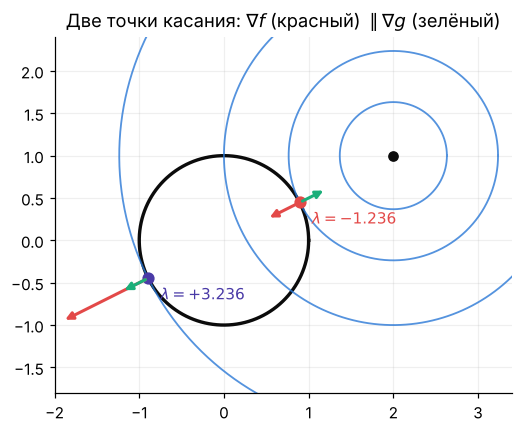

In [4]:
fig, ax = plt.subplots(figsize=(6, 4.2))
unit_circle(ax)                                                         # g = 0
level_circles(ax, a, [0.5 * np.sum((z[:2] - a) ** 2) for z in sols] + [0.2, 2.0], color=BLUE)   # линии уровня f, две — касаются
for z, col in zip(sols, (RED, VIOLET)):
    x = z[:2]
    ax.annotate("", x + 0.35 * grad_f(x), x, arrowprops=dict(arrowstyle="-|>", color=RED, lw=2))       # grad f
    ax.annotate("", x + 0.35 * grad_g(x), x, arrowprops=dict(arrowstyle="-|>", color=AQUA, lw=2))      # grad g
    ax.plot(*x, "o", color=col, ms=7); ax.annotate(f"$\\lambda={z[2]:+.3f}$", x, (8, -14), textcoords="offset points", color=col)
ax.plot(*a, "o", color=INK); ax.set_aspect("equal"); ax.set_xlim(-2, 3.4); ax.set_ylim(-1.8, 2.4)
ax.set_title("Две точки касания: $\\nabla f$ (красный) $\\parallel\\nabla g$ (зелёный)"); plt.show()

## 2. Условие первого порядка: у градиента нет касательной части

**Главная мысль.** В минимуме на кривой или поверхности $g(x)=0$ производная $f$ вдоль любого допустимого направления равна нулю. Допустимые направления — касательные к поверхности; поэтому $\nabla f$ должен быть комбинацией градиентов ограничений. Коэффициенты этой комбинации и есть множители Лагранжа.

### 2.1. Одно ограничение

Пусть $x^\ast$ — минимум $f$ на кривой $g(x)=0$, $g:\mathbb R^n\to\mathbb R$. Проведём через $x^\ast$ любую гладкую кривую $x(t)$, лежащую на поверхности: $g(x(t))=0$ при всех $t$, $x(0)=x^\ast$. Продифференцируем тождество $g(x(t))=0$ по $t$ в нуле:

$$
\nabla g(x^\ast)^\top x'(0)=0 .
$$

Вектор скорости $p=x'(0)\in\mathbb R^n$ — **касательное направление**: оно перпендикулярно $\nabla g$. Теперь посмотрим на $f$ вдоль той же кривой: функция одной переменной $\varphi(t)=f(x(t))$ имеет в $t=0$ минимум, поэтому $\varphi'(0)=\nabla f(x^\ast)^\top p=0$. Так для **каждого** касательного $p$. Вектор, перпендикулярный всем векторам, перпендикулярным $\nabla g$, сам параллелен $\nabla g$:

$$
\nabla f(x^\ast)=\lambda\,\nabla g(x^\ast),\qquad\lambda\in\mathbb R .
$$

Это формула лекции 3, но теперь с выводом — и вывод показывает, где она может сломаться: мы молча считали, что касательных направлений «достаточно» ($n-1$ штук) и что $\nabla g(x^\ast)\ne0$. К этому вернёмся в разделе 3.

**Пример из введения.** $f(x)=\tfrac12\lVert x-a\rVert^2$, $g(x)=\tfrac12(\lVert x\rVert^2-1)$, $a=(2,1)$. Градиенты $\nabla f=x-a$, $\nabla g=x$; условие $x-a=\lambda x$ даёт $x=a/(1-\lambda)$, и из $\lVert x\rVert=1$ получаем $1-\lambda=\pm\lVert a\rVert=\pm\sqrt5$:

$$
\lambda=1-\sqrt5=-1.236,\ \ x^\ast=\frac{a}{\sqrt5}=(0.894,\,0.447),\ \ f=0.764;\qquad
\lambda=1+\sqrt5=3.236,\ \ x=-\frac{a}{\sqrt5},\ \ f=5.236 .
$$

<img src="img/02_circle_two_points.png" width="900" alt="единичная окружность и окружности уровня f вокруг a = (2, 1): две точки касания — ближайшая (0.894, 0.447) с λ = −1.236 и дальняя (−0.894, −0.447) с λ = 3.236; в обеих ∇f и ∇g параллельны, в ближней направлены в одну сторону со знаком минус, в дальней — в разные">

*Две точки, в которых линия уровня касается окружности. Условие первого порядка выполнено в обеих; какая из них минимум, скажет раздел 4.*

### 2.2. Несколько ограничений: якобиан, касательное пространство, функция Лагранжа

Теперь ограничений $m$: $g(x)=0$, $g:\mathbb R^n\to\mathbb R^m$, $m<n$. Их градиенты — строки **якобиана** $J(x)=\dfrac{\partial g}{\partial x}\in\mathbb R^{m\times n}$ (матрица $m\times n$, $j$-я строка — $\nabla g_j^\top$). Тот же вывод: для кривой на поверхности $J(x^\ast)\,x'(0)=0$, так что касательные направления образуют **касательное пространство**

$$
T=\{\,p\in\mathbb R^n:\ J(x^\ast)\,p=0\,\}
$$

— ядро якобиана, размерности $n-m$ (если строки $J$ независимы). Условие $\nabla f^\top p=0$ для всех $p\in T$ означает, что $\nabla f$ лежит в пространстве, перпендикулярном ядру $J$, — а это пространство строк $J$, то есть линейные комбинации градиентов ограничений:

$$
\nabla f(x^\ast)=J(x^\ast)^\top\lambda=\sum_{j=1}^m\lambda_j\nabla g_j(x^\ast),\qquad\lambda\in\mathbb R^m .
$$

Вектор $\lambda$ — **множители Лагранжа** (*Lagrange multipliers*), по одному на ограничение. Удобно завести функцию, градиент которой по $x$ — ровно это равенство:

$$
L(x,\lambda)=f(x)-\lambda^\top g(x),\qquad \nabla_xL=\nabla f-J^\top\lambda .
$$

Это **функция Лагранжа** (знак перед $\lambda$ — как в Л3 §7; в книгах и солверах встречается $+\lambda^\top g$, тогда $\lambda$ меняет знак). Условие первого порядка вместе с допустимостью — система

$$
\boxed{\;\nabla_xL(x^\ast,\lambda^\ast)=0,\qquad g(x^\ast)=0\;}
$$

— $n+m$ уравнений на $n+m$ неизвестных $(x,\lambda)$. В следующей лекции мы будем решать её методом Ньютона; сегодня — учимся её понимать.

<img src="img/03_tangent_space.png" width="900" alt="кривая g = 0 в точке x: касательная прямая T (ядро якобиана) и нормаль ∇g; вектор ∇f разложен на нормальную часть λ∇g и касательную часть; слева точка не оптимальна — касательная часть ненулевая, справа оптимум — ∇f целиком лежит на нормали">

*Разложение $\nabla f$ на часть вдоль $\nabla g$ и часть вдоль касательного пространства $T$. В минимуме касательная часть равна нулю — остаётся $\nabla f=\lambda\nabla g$.*

### Демо (b). Множитель, которого нет (раздел 3)

**Что проверяем.** Клюв $g=x_2^3-x_1^2$, $f=x_2$: минимум в $(0,0)$, но $\nabla g(0,0)=0$. Вдоль кривой к клюву «лучший» множитель $\hat\lambda=\nabla f^\top\nabla g/\lVert\nabla g\rVert^2$ растёт как $x_1^{-2/3}$, а невязка $\lVert\nabla f-\hat\lambda\nabla g\rVert$ стремится к $1$: уравновесить $\nabla f$ нечем. Второй случай — ограничение, записанное дважды: $\operatorname{rank}J=1<2$, множители не единственны, IPOPT возвращает один из них.

In [5]:
print(f"{'x1':>8s} {'|grad g|':>10s} {'lambda^':>9s} {'невязка':>9s} {'угол':>7s}")
for x1 in (0.5, 0.1, 0.01, 0.001, 1e-4):
    gg, lam_hat, ang = cusp_grad(x1)                                    # grad g, оценка lambda, угол к grad f
    res = np.linalg.norm(np.array([0.0, 1.0]) - lam_hat * gg)          # |grad f - lambda^ grad g|
    print(f"{x1:8.0e} {np.linalg.norm(gg):10.4f} {lam_hat:9.2f} {res:9.4f} {ang:6.1f}°")
print("в конспекте: при x1 = 0.1, 0.01, 0.001 — lambda^ = 2.3, 14.6, 73 и угол 55°, 72°, 81°")

      x1   |grad g|   lambda^   невязка    угол
   5e-01     1.5548      0.49    0.6432   40.0°
   1e-01     0.2437      2.34    0.8207   55.2°
   1e-02     0.0210     14.63    0.9515   72.1°
   1e-03     0.0020     73.35    0.9889   81.5°
   1e-04     0.0002    346.44    0.9976   86.0°
в конспекте: при x1 = 0.1, 0.01, 0.001 — lambda^ = 2.3, 14.6, 73 и угол 55°, 72°, 81°


**Повторённое ограничение.** $\min\tfrac12\lVert x-a\rVert^2$ при $x_1+x_2=1$: решение $x^\ast=(1,0)$, $\lambda=-1$ (в нашем знаке). Запишем то же ограничение дважды: $J=\begin{pmatrix}1&1\\1&1\end{pmatrix}$ ранга $1$, и любые $\lambda_1+\lambda_2=-1$ решают $\nabla f=J^\top\lambda$. IPOPT не ломается — он возвращает $\lambda_1=\lambda_2$ (а в `lam_g` знак противоположный нашему).

In [6]:
x = ca.SX.sym("x", 2)
f = 0.5 * ca.sumsqr(x - ca.DM([2, 1]))                                 # f = 1/2 |x - a|^2
g1 = x[0] + x[1] - 1                                                   # одно ограничение
for name, g in (("одно ограничение", g1), ("то же дважды", ca.vertcat(g1, g1)), ("g и 2g", ca.vertcat(g1, 2 * g1))):
    s = ca.nlpsol("s", "ipopt", {"x": x, "f": f, "g": g}, {"ipopt.print_level": 0, "print_time": 0, "ipopt.sb": "yes"})
    sol = s(x0=[0, 0], lbg=0, ubg=0)                                   # равенство: lbg = ubg = 0
    J = ca.Function("J", [x], [ca.jacobian(g, x)])(sol["x"]).full()    # якобиан в решении
    print(f"{name:18s}: x* = {np.array(sol['x']).ravel()}, rank J = {np.linalg.matrix_rank(J)}, lam (наш знак) = {-np.array(sol['lam_g']).ravel()}")

одно ограничение  : x* = [1. 0.], rank J = 1, lam (наш знак) = [-1.]
то же дважды      : x* = [1.00000000e+00 1.40585332e-09], rank J = 1, lam (наш знак) = [-0.5 -0.5]
g и 2g            : x* = [1.00000000e+00 5.62341321e-10], rank J = 1, lam (наш знак) = [-0.19999998 -0.40000001]


## 3. LICQ: когда множителей нет

**Главная мысль.** Вывод раздела 2 опирается на то, что касательное пространство честно описывает допустимые направления. Это так, если градиенты ограничений в точке линейно независимы. Иначе минимум может быть, а множителей — нет.

### 3.1. Пример: клюв

Возьмём $f(x)=x_2$ и одно ограничение $g(x)=x_2^3-x_1^2=0$, то есть $x_2=x_1^{2/3}$ — кривая с остриём («клювом») в начале координат. Минимум $x_2$ на ней — очевидно $x^\ast=(0,0)$. Но $\nabla g=(-2x_1,\,3x_2^2)=(0,0)$ в этой точке, а $\nabla f=(0,1)$: уравнение $(0,1)=\lambda\,(0,0)$ не имеет решений ни при каком $\lambda$. Система раздела 2 **не находит** настоящий минимум.

<img src="img/04_cusp_licq.png" width="900" alt="слева: кривая x₂ = x₁^(2/3) с клювом в нуле, стрелки ∇g в точках x₁ = 0.5, 0.1, 0.01 — укорачиваются и ложатся горизонтально, а ∇f = (0, 1) всегда вертикален; справа: угол между ∇f и ∇g и оценка λ по наименьшим квадратам как функции x₁ — угол стремится к 90°, λ растёт как x₁^(−2/3)">

*Вдоль кривой к клюву: $\nabla g$ укорачивается и ложится горизонтально, угол между $\nabla f$ и $\nabla g$ растёт к $90^\circ$ (при $x_1=0.1$ — $55^\circ$, при $0.01$ — $72^\circ$, при $0.001$ — $81^\circ$), а «лучший» множитель $\lambda$ растёт как $x_1^{-2/3}$: $2.3$, $14.6$, $73$. Уравновесить $\nabla f$ градиентом ограничения нельзя.*

<img src="img/10_licq_breaks.gif" width="900" alt="анимация: точка скользит по кривой x₂ = x₁^(2/3) к клюву, стрелка ∇g укорачивается и поворачивается горизонтально, в заголовке растёт оценка λ">

*Точка скользит к клюву; в заголовке — $\lVert\nabla g\rVert$ и оценка $\lambda$.*

Что сломалось: в $(0,0)$ градиент ограничения нулевой, «касательное пространство» $\{p:\nabla g^\top p=0\}$ — вся плоскость, а настоящих допустимых направлений — одно, вверх по оси $x_2$. Вывод раздела 2 обещал кривые на поверхности с любой касательной $p$ — здесь таких кривых нет.

### 3.2. Условие регулярности и теорема

**Определение.** В точке $x$ выполнено **условие линейной независимости** (*linear independence constraint qualification*, **LICQ**), если градиенты ограничений $\nabla g_1(x),\dots,\nabla g_m(x)$ линейно независимы, то есть $\operatorname{rank}J(x)=m$. Для одного ограничения это просто $\nabla g(x)\ne0$.

**Что обещает теорема.** В локальном минимуме с LICQ множители существуют и единственны — система раздела 2 его обязательно найдёт. **Почему.** При LICQ поверхность $g=0$ около $x^\ast$ можно гладко параметризовать $n-m$ свободными координатами (теорема о неявной функции), и задача становится задачей *без ограничений* на $n-m$ переменных; условие $\nabla f=0$ для неё и есть $\nabla f\in\operatorname{range}J^\top$. **Чего не обещает.** Достаточности: как показала окружность, решений системы может быть несколько, и среди них — максимумы и сёдла.

**Теорема (необходимое условие первого порядка).** Пусть $f$ и $g$ непрерывно дифференцируемы, $x^\ast$ — локальный минимум $f$ при $g(x)=0$ и в $x^\ast$ выполнено LICQ. Тогда существует единственный $\lambda^\ast\in\mathbb R^m$ такой, что $\nabla_xL(x^\ast,\lambda^\ast)=0$ и $g(x^\ast)=0$.

**Идея доказательства — три строки.**

1. *Параметризуем поверхность.* Строки $J(x^\ast)$ независимы, поэтому по теореме о неявной функции около $x^\ast$ множество $g=0$ — график гладкого отображения $x=\psi(u)$, $u\in\mathbb R^{n-m}$, причём столбцы $\partial\psi/\partial u$ образуют базис касательного пространства $T=\ker J(x^\ast)$.
2. *Сводим к задаче без ограничений.* $u^\ast$ — локальный минимум $\varphi(u)=f(\psi(u))$, значит $\nabla\varphi(u^\ast)=(\partial\psi/\partial u)^\top\nabla f(x^\ast)=0$: градиент $\nabla f$ перпендикулярен $T$.
3. *Перпендикуляр к ядру — это строки.* $T^\perp=\operatorname{range}J(x^\ast)^\top$, откуда $\nabla f=J^\top\lambda$; единственность — из независимости строк $J$.

Полное доказательство — разбор упражнения 8.6.

### 3.3. Что LICQ значит численно

Нарушение LICQ встречается чаще, чем клювы: достаточно **записать одно ограничение дважды** или два ограничения, задающие одну поверхность (например, $x_1+x_2=1$ и $2x_1+2x_2=2$). Минимум на месте, но якобиан неполного ранга, и множители не единственны: любые $\lambda_1+\lambda_2=\lambda$ подходят (демо (b)). Для Ньютона–Лагранжа лекции 9 это означает вырожденную матрицу системы — солверы отвечают на это регуляризацией и предупреждениями. Правило простое: **ограничения должны быть независимыми** — не повторяться и не следовать друг из друга.

## 4. Условие второго порядка: кривизна вдоль касательной

**Главная мысль.** Является ли точка минимумом, решает кривизна — но не кривизна $f$, а кривизна **функции Лагранжа**, и только **вдоль касательного пространства**. Кривизна ограничений входит в ответ наравне с кривизной $f$.

### 4.1. Две параболы

Возьмём линейную функцию $f(x)=x_2$ — у неё нет никакой кривизны, $\nabla^2f=0$, — и будем минимизировать её на параболе $g(x)=x_2-c\,x_1^2=0$. Градиенты: $\nabla f=(0,1)$, $\nabla g=(-2cx_1,\,1)$; в $x^\ast=(0,0)$ они совпадают, $\lambda=1$ при любом $c$. Система первого порядка одна и та же, а ответ разный: при $c=1$ парабола смотрит вверх и $(0,0)$ — её нижняя точка, **минимум**; при $c=-1$ парабола смотрит вниз, $(0,0)$ — **максимум** $x_2$ на ней.

<img src="img/05_parabola_curvature.png" width="900" alt="две панели: f = x₂ на параболе x₂ = x₁² (слева, минимум в нуле) и на параболе x₂ = −x₁² (справа, максимум в нуле); линии уровня f горизонтальны, в нуле ∇f = ∇g = (0, 1) на обеих панелях, одинаковое условие первого порядка, разный ответ">

*Одно и то же условие первого порядка, $\lambda=1$, — и минимум слева, максимум справа. Разница только в кривизне ограничения.*

Посмотрим на $f$ вдоль кривой: параметризуем параболу $x(t)=(t,\,ct^2)$, тогда $\varphi(t)=f(x(t))=ct^2$ и $\varphi''(0)=2c$. Знак $c$ и решает. Та же величина получается из функции Лагранжа: $\nabla^2_{xx}L=\nabla^2f-\lambda\nabla^2g=0-1\cdot\begin{pmatrix}-2c&0\\0&0\end{pmatrix}=\begin{pmatrix}2c&0\\0&0\end{pmatrix}$, и вдоль касательного направления $p=(1,0)$ получаем $p^\top\nabla^2_{xx}L\,p=2c$. Вся кривизна пришла из члена $-\lambda\nabla^2g$.

<img src="img/06_curve_cut.png" width="900" alt="функция f вдоль кривой: φ(t) = f(x(t)) для трёх парабол c = 1, 0, −1 — выпуклая парабола с минимумом, прямая и вогнутая парабола с максимумом; подпись: φ''(0) = pᵀ∇²L p = 2c">

*Разрез $f$ вдоль допустимой кривой — как разрез $\varphi(\alpha)$ вдоль шага в лекции 6. Его вторая производная в нуле равна $p^\top\nabla^2_{xx}L\,p$.*

### 4.2. Редуцированный гессиан и теорема

В общем случае дважды дифференцируем $\varphi(t)=f(x(t))$ вдоль кривой на поверхности, $x(0)=x^\ast$, $x'(0)=p\in T$:

$$
\varphi''(0)=p^\top\nabla^2f(x^\ast)\,p+\nabla f(x^\ast)^\top x''(0).
$$

Второй член содержит $x''(0)$ — как кривая изгибается, чтобы остаться на поверхности. Избавимся от него, продифференцировав дважды тождество $g_j(x(t))=0$: $p^\top\nabla^2g_j\,p+\nabla g_j^\top x''(0)=0$. Умножим на $\lambda_j^\ast$, сложим по $j$ и подставим $\nabla f=\sum_j\lambda^\ast_j\nabla g_j$:

$$
\varphi''(0)=p^\top\Big(\nabla^2f(x^\ast)-\sum_j\lambda_j^\ast\nabla^2g_j(x^\ast)\Big)p=p^\top\nabla^2_{xx}L(x^\ast,\lambda^\ast)\,p .
$$

Кривизна $f$ вдоль поверхности — это кривизна функции Лагранжа вдоль касательного пространства. Если $Z\in\mathbb R^{n\times(n-m)}$ — матрица, столбцы которой образуют базис $T=\ker J(x^\ast)$ (в SciPy — `scipy.linalg.null_space(J)`), то все такие кривизны собирает матрица $(n-m)\times(n-m)$

$$
\nabla^2_{\text{red}}L=Z^\top\nabla^2_{xx}L(x^\ast,\lambda^\ast)\,Z
$$

— **редуцированный гессиан** (*reduced Hessian*).

**Что обещает теорема.** Если в точке, где выполнено условие первого порядка, редуцированный гессиан положительно определён, точка — строгий локальный минимум; в минимуме он обязан быть неотрицательно определён. **Почему.** Вдоль каждой допустимой кривой $f$ ведёт себя как $\varphi(t)=\varphi(0)+\tfrac12\varphi''(0)t^2+\dots$ с $\varphi''(0)=p^\top\nabla^2_{xx}L\,p$. **Чего не обещает.** Ничего о направлениях вне $T$: там $\nabla^2_{xx}L$ может быть каким угодно, это не мешает минимуму (упражнение 8.3).

**Теорема (условия второго порядка).** Пусть $f$, $g$ дважды непрерывно дифференцируемы, в $x^\ast$ выполнено LICQ и $\nabla_xL(x^\ast,\lambda^\ast)=0$, $g(x^\ast)=0$. *Необходимо:* если $x^\ast$ — локальный минимум, то $Z^\top\nabla^2_{xx}L(x^\ast,\lambda^\ast)Z\succeq0$. *Достаточно:* если $Z^\top\nabla^2_{xx}L(x^\ast,\lambda^\ast)Z\succ0$, то $x^\ast$ — строгий локальный минимум.

**Идея доказательства — три строки.** Необходимость: для любого $p\in T$ есть допустимая кривая с $x'(0)=p$ (LICQ), и $\varphi''(0)=p^\top\nabla^2_{xx}L\,p\ge0$ в минимуме. Достаточность: в параметризации $x=\psi(u)$ из раздела 3 функция $\varphi(u)=f(\psi(u))$ имеет $\nabla\varphi(u^\ast)=0$ и $\nabla^2\varphi(u^\ast)=Z^\top\nabla^2_{xx}L\,Z\succ0$, а для задачи без ограничений это достаточное условие лекции 4. Подробно — разбор упражнения 8.6.

### 4.3. Окружность и заполненная таблица

Вернёмся к введению. $\nabla^2f=I$, $\nabla^2g=I$, поэтому $\nabla^2_{xx}L=(1-\lambda)I$: в точке с $\lambda=1-\sqrt5$ это $\sqrt5\,I\succ0$ — **минимум**; с $\lambda=1+\sqrt5$ — это $-\sqrt5\,I\prec0$ — **максимум**. Касательное пространство здесь одномерно, $Z=(-x_2,\,x_1)^\top$, и редуцированный гессиан — число $\pm\sqrt5$. Здесь $\nabla^2_{xx}L$ оказался определённым и вне $T$ — так бывает не всегда, на параболах из §4.1 $\nabla^2_{xx}L=\operatorname{diag}(2c,0)$ вырожден, а редуцированный гессиан $2c$ отвечает чётко.

| | Без ограничений (Л4) | С равенствами $g(x)=0$ |
|---|---|---|
| Неизвестных | $n$ | $n+m$: точка $x$ и множители $\lambda$ |
| Первый порядок | $\nabla f=0$ | $\nabla_xL=\nabla f-J^\top\lambda=0$, $g=0$ (при LICQ) |
| Второй порядок | $\nabla^2f\succ0$ | $Z^\top\nabla^2_{xx}L\,Z\succ0$, $Z$ — базис $\ker J$ |

### Демо (c). Цепь на стержнях в IPOPT (раздел 5)

**Что проверяем.** $80$ координат, $41$ равенство. IPOPT из опущенной прямой $z=0$ — $13$ итераций. Три проверки таблицы раздела 4: невязка стационарности $\lVert\nabla f-J^\top\lambda\rVert\approx10^{-12}$, $\operatorname{rank}J=41$ (LICQ), редуцированный гессиан $39\times39$ положительно определён. Множители — натяжения; горизонтальная составляющая $2\lambda_j\Delta y_j$ одинакова во всех стержнях. **Предскажите до запуска:** сколько ньютонов в вертикальных составляющих на двух опорах вместе? (Вес цепи — $40\cdot0.981=39.24$ Н.)

In [7]:
ch = rod_chain()                                                       # задача: v = (y_1..y_40, z_1..z_40), g_j = |p_{j+1} - p_j|^2 - ell^2
v, lam, st = solve_rod_chain(ch)                                       # IPOPT из прямой z = 0
chk = chain_checks(ch, v, lam)                                         # невязка, ранг J, редуцированный гессиан, силы
print(f"итераций {st['iter_count']} (в конспекте 13);  |grad f - J^T lam| = {chk['res']:.1e}")
print(f"rank J = {chk['rank']} из 41 — LICQ выполнено;  Z: {chk['Z'].shape} — базис касательного пространства размерности 80 - 41 = 39")
print(f"редуцированный гессиан Z^T H_L Z: собственные числа от {chk['eig'].min():.2f} до {chk['eig'].max():.1f} — все > 0, строгий минимум")
print(f"множители: концы {lam[0]:.2f}, середина {lam[20]:.2f} (в конспекте -97.9 и -55.8)")

итераций 13 (в конспекте 13);  |grad f - J^T lam| = 1.2e-13
rank J = 41 из 41 — LICQ выполнено;  Z: (80, 39) — базис касательного пространства размерности 80 - 41 = 39
редуцированный гессиан Z^T H_L Z: собственные числа от 2.17 до 680.6 — все > 0, строгий минимум
множители: концы -97.88, середина -55.76 (в конспекте -97.9 и -55.8)


горизонтальная составляющая 2 lam_j dy_j: -13.6007 … -13.6007 Н — одинакова во всех стержнях
вертикальные на опорах: 19.62 + 19.62 = 39.24 Н = вес цепи 39.24 Н


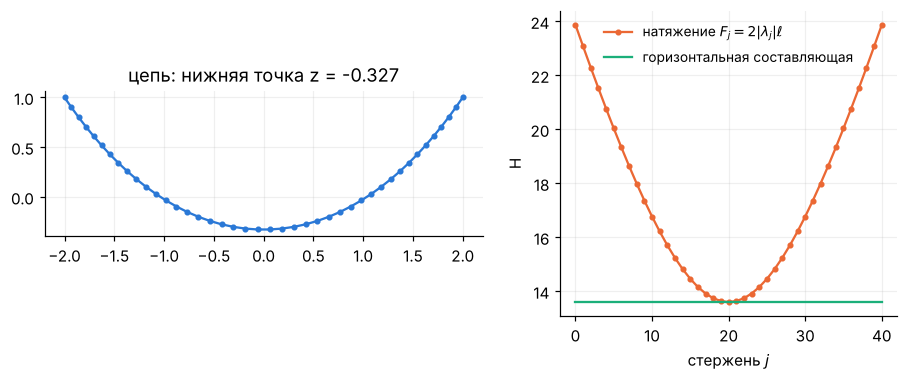

In [8]:
Fh, Fv = chk["Fh"], chk["Fv"]                                          # горизонтальная и вертикальная составляющие силы стержня j
print(f"горизонтальная составляющая 2 lam_j dy_j: {Fh.min():.4f} … {Fh.max():.4f} Н — одинакова во всех стержнях")
print(f"вертикальные на опорах: {abs(Fv[0]):.2f} + {abs(Fv[-1]):.2f} = {abs(Fv[0]) + abs(Fv[-1]):.2f} Н = вес цепи {ch['w'] * ch['N']:.2f} Н")
y, z = chain_xy(ch, v)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw=dict(width_ratios=[1.3, 1]))
axes[0].plot(y, z, "o-", color=BLUE, ms=3); axes[0].set_aspect("equal"); axes[0].set_title(f"цепь: нижняя точка z = {z.min():.3f}")
axes[1].plot(chk["F"], "o-", color=ORANGE, ms=3, label="натяжение $F_j=2|\\lambda_j|\\ell$")
axes[1].plot(np.abs(Fh), color=AQUA, label="горизонтальная составляющая"); axes[1].set_xlabel("стержень $j$"); axes[1].set_ylabel("Н"); axes[1].legend(fontsize=9)
plt.show()

## 5. Сквозные задачи: силы и цены

**Главная мысль.** Множители — не вспомогательные числа, а ответ на вопрос «с какой силой держит ограничение» и «сколько стоит его сдвинуть». У цепи на стержнях это натяжения в ньютонах, у портфеля — риск за процент доходности.

### 5.1. Цепь на стержнях: $\lambda$ — натяжение

Грузы $i=1,\dots,40$ с координатами $(y_i,z_i)$, концы закреплены в $(-2,1)$ и $(2,1)$, стержень $j=0,\dots,40$ соединяет грузы $j$ и $j+1$ (груз $0$ и $41$ — опоры). Задача:

$$
\min_{x\in\mathbb R^{80}}\ f(x)=w\sum_{i=1}^{40}z_i\qquad\text{при}\qquad g_j(x)=(y_{j+1}-y_j)^2+(z_{j+1}-z_j)^2-\ell^2=0,\quad j=0,\dots,40,
$$

$w=0.981$ Н, $\ell=5/41$. Якобиан $J$ — матрица $41\times80$, в строке $j$ четыре ненулевых числа: $\pm2(y_{j+1}-y_j)$ и $\pm2(z_{j+1}-z_j)$. Условие $\nabla_xL=0$ для груза $i$ — два уравнения:

$$
\lambda_{i-1}\cdot2(y_i-y_{i-1})-\lambda_i\cdot2(y_{i+1}-y_i)=0,\qquad
\lambda_{i-1}\cdot2(z_i-z_{i-1})-\lambda_i\cdot2(z_{i+1}-z_i)=w .
$$

Это баланс сил: стержень $j$ тянет груз с силой $2\lambda_j\,(\Delta y_j,\Delta z_j)$, величина которой $F_j=2\lvert\lambda_j\rvert\,\ell$ — **натяжение**. Первое уравнение говорит, что горизонтальная составляющая натяжения $2\lambda_j\Delta y_j$ одинакова во всех стержнях, второе — что разность вертикальных составляющих соседних стержней равна весу груза. Так из условия первого порядка следует классическое свойство цепной линии, и его можно проверить числами.

<img src="img/07_chain_rods.png" width="900" alt="слева: цепь из 40 грузов на стержнях между (−2, 1) и (2, 1), нижняя точка z = −0.327, стрелки натяжений на концах и в середине; справа: натяжение F_j по номеру стержня — 23.9 Н на концах, 13.6 Н в середине, и горизонтальная составляющая — горизонтальная прямая 13.6 Н">

*IPOPT из опущенной прямой $z=0$: $13$ итераций, $f^\ast=5.756$ Дж, нижняя точка $z=-0.327$. Множители (в нашем знаке) от $-97.9$ на концах до $-55.8$ в середине; натяжение $F_j=2\lvert\lambda_j\rvert\ell$ — от $23.9$ Н до $13.6$ Н, горизонтальная составляющая $13.6$ Н во всех $41$ стержнях. Вертикальная составляющая на опорах — $19.6$ Н, половина веса цепи $39.2$ Н.*

Три проверки из таблицы раздела 4 (демо (c)): невязка $\lVert\nabla f-J^\top\lambda\rVert\approx10^{-12}$; $\operatorname{rank}J=41$ — LICQ выполнено; редуцированный гессиан $39\times39$ ($n-m=80-41$) имеет собственные числа от $2.2$ до $681$ — все положительные, строгий минимум. Заметьте: $\nabla^2f=0$, вся кривизна — $-\sum_j\lambda_j\nabla^2g_j=-2\sum_j\lambda_j(\dots)$ с отрицательными $\lambda_j$. **Минимум держат стержни, а не функция.**

### 5.2. Портфель: $\lambda$ — цена, и формула чувствительности

Портфель лекции 3 (§2.2) с целью доходности $10\,\%$: $\min\tfrac12x^\top\Sigma x$ при двух равенствах — бюджет $\mathbf 1^\top x=1$ и доходность $r^\top x=\rho$. При $\rho=0.10$ все доли положительны, $x^\ast=(0.095,\,0.382,\,0.321,\,0.202)$, так что запрет коротких позиций не активен и задача — ровно с двумя равенствами; $f^\ast=0.00820$ (волатильность $12.8\,\%$), множители $\lambda_{\text{бюдж}}=-0.0093$, $\lambda_\rho=0.257$.

Лекция 3 обещала доказать, что множитель — это производная оптимума по правой части. Для равенств доказательство — две строки. Рассмотрим семейство задач $g(x)=b$ и его оптимум $f^\ast(b)=f(x^\ast(b))$. На решении $g(x^\ast(b))=b$, поэтому $f^\ast(b)=L(x^\ast(b),\lambda^\ast(b),b)$ с $L=f-\lambda^\top(g(x)-b)$. Дифференцируем по $b$: члены с $\partial x^\ast/\partial b$ умножаются на $\nabla_xL=0$, члены с $\partial\lambda^\ast/\partial b$ — на $g-b=0$, остаётся

$$
\frac{\partial f^\ast}{\partial b}=\frac{\partial L}{\partial b}=\lambda^\ast .
$$

<img src="img/08_portfolio_price.png" width="900" alt="слева: минимальный риск f*(ρ) как функция цели доходности ρ от 6 до 14 %, касательная в ρ = 10 % с наклоном λ_ρ = 0.257; справа: энергия цепи на стержнях как функция общей длины L от 4.9 до 5.1, касательная в L = 5 с наклоном, предсказанным множителями">

*Слева: $f^\ast(\rho)$ и касательная с наклоном $\lambda_\rho=0.257$ — лишний процентный пункт доходности стоит $0.0026$ риска. Справа: удлиняем все стержни цепи на $1\,\%$: по множителям $f^\ast$ должна упасть с $5.756$ до $4.873$ Дж, пересчёт даёт $4.886$ — разница в $0.013$ есть эффект второго порядка.*

## 6. Что это даёт численно

**Солверы возвращают множители.** IPOPT через CasADi — `sol["lam_g"]`, со знаком $L=f+\lambda^\top g$, то есть $\lambda_{\text{наш}}=-$`lam_g`; `scipy.optimize.minimize(method="trust-constr")` — `res.v`; `linprog` — `marginals` (Л3). Первое, что стоит сделать с ответом солвера, — подставить $x^\ast$ и $\lambda^\ast$ в систему раздела 2 и посчитать две невязки.

**Лог IPOPT — это две невязки.** Колонка `inf_pr` (*primal infeasibility*) — $\lVert g(x_k)\rVert_\infty$, колонка `inf_du` (*dual infeasibility*) — $\lVert\nabla_xL(x_k,\lambda_k)\rVert_\infty$. Солвер останавливается, когда обе меньше `tol`.

<img src="img/09_ipopt_residuals.png" width="900" alt="невязки IPOPT на цепи на стержнях по итерациям из старта z = 0: inf_pr (нарушение ограничений) от 1 и inf_du (норма ∇ₓL) от 1 — обе падают до 1e−14 за 13 итераций, в логарифмической шкале; пунктир — tol = 1e−8">

*Обе невязки на цепи на стержнях: допустимость и стационарность сходятся вместе — в лекции 9 увидим, что это один шаг Ньютона по системе $(x,\lambda)$.*

**Старт имеет значение.** Из горизонтальной прямой $z=1$ тот же IPOPT делает $32$ итерации, и `inf_du` по дороге доходит до $10^{13}$: на прямой все стержни коллинеарны, и вертикальное смещение не меняет ни одной длины в первом порядке — у $J$ «не видно» целого направления, задача почти вырождена. Старт с прогибом — $5$–$13$ итераций.

## 7. Итоги лекции

1. На поверхности $g(x)=0$ допустимые направления — касательное пространство $T=\ker J(x^\ast)$; в минимуме $\nabla f\perp T$, то есть $\nabla f=J^\top\lambda$ — множители Лагранжа, по одному на ограничение (§2).
2. Функция Лагранжа $L=f-\lambda^\top g$ собирает условие первого порядка и допустимость в систему $\nabla_xL=0$, $g=0$: $n+m$ уравнений на $(x,\lambda)$ (§2.2).
3. Система работает при LICQ — градиенты ограничений линейно независимы; без него минимум может быть, а множителей нет (клюв) или их много (повторённое ограничение) (§3).
4. Минимум от максимума отличает кривизна функции Лагранжа вдоль $T$: редуцированный гессиан $Z^\top\nabla^2_{xx}L\,Z\succ0$ — достаточно, $\succeq0$ — необходимо; кривизна ограничений входит через $-\lambda\nabla^2g$ (§4).
5. Множитель — сила ограничения (натяжение стержня $2\lvert\lambda_j\rvert\ell$) и цена ограничения ($\partial f^\ast/\partial b=\lambda^\ast$); солверы возвращают их вместе с $x^\ast$, а лог IPOPT показывает невязки обеих половин системы (§5–6).

## 8. Что дальше

**Лекция 9** — алгоритмы для равенств: метод Ньютона по системе $\nabla_xL=0$, $g=0$ (Ньютон–Лагранж), матрица ККТ $\begin{pmatrix}\nabla^2_{xx}L&J^\top\\J&0\end{pmatrix}$, обобщённый Гаусс–Ньютон, range-space и null-space; цепь на стержнях — своим методом против IPOPT. **Лекция 10** — неравенства: условия ККТ целиком, регулярность, двойственность.

**ДЗ 4** — срок 4 ноября ([карточка](../../homeworks/hw04.md)). ДЗ 5 (равенства: Ньютон–Лагранж и обобщённый Гаусс–Ньютон) выдаётся после лекции 9.

**Литература к лекции.**
- Diehl, *Lecture Notes on Numerical Optimization*, часть III, глава *Equality Constrained Optimization*: касательное пространство, LICQ, условия первого и второго порядка.
- Nocedal & Wright, гл. 12: §12.1 — примеры, §12.2 — касательный конус и LICQ, §12.3 — теорема первого порядка, §12.5 — условия второго порядка.
- Boyd & Vandenberghe, §10.1 — задачи с равенствами и система ККТ; §5.6 — множители как чувствительность.

## 9. Упражнения

Разбор с проверкой кодом — [`exercises08.ipynb`](exercises08.ipynb), краткие ответы — [`exercises08.md`](exercises08.md). На семинаре — 8.0 и 8.3; остальные домашние.

**8.0. Разминка — счёт руками.** *Суть: система $\nabla_xL=0$, $g=0$ на трёх задачах с известным ответом.*

- (а) Ближайшая к $x_0$ точка плоскости $a^\top x=b$. Выпишите $L$, решите систему, выразите $\lambda$ через $a$, $b$, $x_0$ и проверьте, что ответ — проекция из лекции 2.
- (б) $\min x_1+x_2$ при $x_1^2+x_2^2=1$: оба решения системы, их $\lambda$, какое из них минимум.
- (в) Ящик наибольшего объёма при площади поверхности $6$ (Л3, упражнение 13.10): найдите $\lambda$ в решении $x=y=z=1$ и объясните его знак (задача на максимум).

**8.1. Две точки на окружности** (с кодом). *Суть: редуцированный гессиан различает минимум и максимум.*

- (а) Решите систему из §2.1 методом `fsolve` из двух стартов, получите обе точки и оба $\lambda$.
- (б) Для каждой постройте $Z$ (`null_space`), редуцированный гессиан и скажите, что это за точка. Повторите для $a=(0.3,0.1)$ — что изменилось?

**8.2. Клюв** (с кодом). *Суть: без LICQ множитель растёт неограниченно.*

Вдоль кривой $x_2=x_1^{2/3}$ при $x_1=10^{-1},\dots,10^{-6}$ посчитайте $\lVert\nabla g\rVert$, оценку $\lambda=\nabla f^\top\nabla g/\lVert\nabla g\rVert^2$ и невязку $\lVert\nabla f-\lambda\nabla g\rVert$. Покажите, что $\lambda\sim x_1^{-2/3}$, а невязка стремится к $1$. Замените ограничение на $g=x_2-x_1^{2/3}$ — ту же кривую: что с LICQ теперь?

**8.3. Кривизна ограничения.** *Суть: $\nabla^2f$ ничего не решает, решает $\nabla^2_{xx}L$ вдоль $T$.*

- (а) $f=x_2$ на $x_2=cx_1^2$: при каких $c$ начало координат — минимум, максимум, ни то ни другое? Что такое «ни то ни другое» здесь?
- (б) $f=x_1^2-x_2^2$ (седло в нуле) на прямой $x_2=0$: покажите, что $(0,0)$ — строгий минимум, хотя $\nabla^2f$ индефинитен (собственные числа разных знаков).

**8.4. Цепь на стержнях: силы и цена длины** (с кодом). *Суть: условие первого порядка — это баланс сил, множитель — производная оптимума.*

- (а) Решите задачу §5.1 в CasADi, получите $\lambda$ и проверьте: горизонтальная составляющая $2\lambda_j\Delta y_j$ одинакова во всех стержнях, вертикальные на опорах в сумме дают вес цепи.
- (б) Удлините стержни на $1\,\%$ и на $5\,\%$; сравните изменение $f^\ast$ с предсказанием $\sum_j\lambda_j\,\Delta(\ell^2)$. Почему при $5\,\%$ расхождение больше?

**8.5. Цена доходности** (с кодом). *Суть: $\partial f^\ast/\partial\rho=\lambda_\rho$.*

Портфель §5.2: решите систему ККТ (она линейная — почему?) для $\rho$ от $6$ до $14\,\%$, постройте $f^\ast(\rho)$ и сравните её численную производную с $\lambda_\rho$. При какой цели $\rho$ доля первого актива становится отрицательной — и что тогда происходит с задачей лекции 3, где $x\ge0$?

**8.6. Для желающих: доказательства.** *Суть: теорема о неявной функции делает из задачи с равенствами задачу без них.*

Докажите теоремы §3.2 и §4.2 полностью: параметризация $x=\psi(u)$, формулы для $\nabla\varphi$ и $\nabla^2\varphi$, почему столбцы $\partial\psi/\partial u$ — базис $\ker J$. Докажите формулу чувствительности §5.2, аккуратно проверив, что $x^\ast(b)$ и $\lambda^\ast(b)$ дифференцируемы (какое условие второго порядка для этого нужно?).

## Вопросы для самопроверки

1. Почему в минимуме на поверхности $g=0$ градиент $\nabla f$ обязан лежать в пространстве строк якобиана $J$?
2. Сколько уравнений и неизвестных в системе условий первого порядка при $n$ переменных и $m$ ограничениях?
3. Что такое LICQ и какой пример показывает, что без него множителей может не быть?
4. Почему условие второго порядка проверяет $\nabla^2_{xx}L$, а не $\nabla^2f$? Приведите пример, где $\nabla^2f=0$, а минимум есть.
5. Что такое редуцированный гессиан и какого он размера?
6. Какой знак у множителей цепи на стержнях в нашем соглашении $L=f-\lambda^\top g$ и что означает их величина?
7. Что показывают колонки `inf_pr` и `inf_du` лога IPOPT?
8. Задача записана с ограничением $x_1+x_2=1$ дважды. Найдёт ли солвер минимум? Что будет с множителями?